In [252]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

RANDOM_STATE = 42

## Data Ingestion and Cleaning

In [253]:
df = pd.read_csv('sarcasm_cleanedV2.csv')

df.head()

,is_sarcastic,headline,cleaned_headline
0,1,thirtysomething scientists unveil doomsday clo...,thirtysomething scientists unveil doomsday clo...
1,0,dem rep. totally nails why congress is falling...,dem rep totally nails congress falling short g...
2,0,eat your veggies: 9 deliciously different recipes,eat veggies 9 deliciously different recipes
3,1,inclement weather prevents liar from getting t...,inclement weather prevents liar getting work
4,1,mother comes pretty close to using word 'strea...,mother comes pretty close using word streaming...


In [254]:
print("Shape of the dataset:", df.shape)

Shape of the dataset: (28503, 3)


In [255]:
print("Number of missing values in each column:")
print(df.isnull().sum())

Number of missing values in each column:
is_sarcastic        0
headline            0
cleaned_headline    1
dtype: int64


In [256]:
# Dropping the only missing row
df = df.dropna()

print("Number of missing values after handling nulls:")
print(df.isnull().sum())

Number of missing values after handling nulls:
is_sarcastic        0
headline            0
cleaned_headline    0
dtype: int64


In [257]:
print("Number of duplicate rows in the dataset:", df.duplicated().sum())

Number of duplicate rows in the dataset: 0


## Straified splitting 70/15/15 

In [258]:
X = df['cleaned_headline']
y = df['is_sarcastic']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])
print("—" * 50)
print(f"Training set class distribution: {y_train.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nValidation set class distribution: {y_val.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nTest set class distribution: {y_test.value_counts(normalize=True).map('{:.3f}'.format)}")

Training set size: 19951
Validation set size: 4275
Test set size: 4276
——————————————————————————————————————————————————
Training set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object

Validation set class distribution: is_sarcastic
0    0.524
1    0.476
Name: proportion, dtype: object

Test set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object


## TF-IDF Vectorization

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [260]:
max_features_list = [10000, 20000, 50000, 100000]
C_list = [0.1, 1, 10, 100]
results = []

for max_features in max_features_list:
    vectorizer = TfidfVectorizer(max_features=max_features, ngram_range=(1, 2))
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_val_tfidf = vectorizer.transform(X_val)

    for c in C_list:
        model = LogisticRegression(C=c, random_state=RANDOM_STATE, max_iter=10000)
        model.fit(X_train_tfidf, y_train)

        results.append({
            "max_features": max_features,
            "C": c,
            "train_f1": f1_score(y_train, model.predict(X_train_tfidf)),
            "val_f1": f1_score(y_val, model.predict(X_val_tfidf)),
        })

results_df = pd.DataFrame(results)
results_df["gap"] = results_df["train_f1"] - results_df["val_f1"]
results_df = results_df.round(4)
results_df.sort_values(by=["val_f1", "train_f1"], ascending=False, inplace=True)
results_df

,max_features,C,train_f1,val_f1,gap
15,100000,100.0,0.9998,0.8033,0.1965
14,100000,10.0,0.9993,0.8020,0.1973
10,50000,10.0,0.9915,0.7971,0.1943
11,50000,100.0,0.9995,0.7962,0.2033
6,20000,10.0,0.9790,0.7919,0.1871
2,10000,10.0,0.9390,0.7873,0.1517
9,50000,1.0,0.9153,0.7830,0.1323
7,20000,100.0,0.9974,0.7825,0.2148
5,20000,1.0,0.8968,0.7825,0.1143
13,100000,1.0,0.9377,0.7794,0.1584


In [261]:
# Final TF-IDF vectorizer (max_features=150000, ngram_range=(1,2))
vectorizer = TfidfVectorizer(max_features=150000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

In [269]:
print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())}")
print("Max features: 150000")
print("ngram_range: (1, 2)\n")
print(f"Shape of the TF-IDF matrix for training set: {X_train_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for validation set: {X_val_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for test set: {X_test_tfidf.shape}") 

Vocabulary size: 130804
Max features: 150000
ngram_range: (1, 2)

Shape of the TF-IDF matrix for training set: (19951, 130804)
Shape of the TF-IDF matrix for validation set: (4275, 130804)
Shape of the TF-IDF matrix for test set: (4276, 130804)


## Logistic Regression Model

C=1: Train F1 Score=0.9503, Validation F1 Score=0.7937
C=2: Train F1 Score=0.9763, Validation F1 Score=0.8014
C=3: Train F1 Score=0.9885, Validation F1 Score=0.8043
C=5: Train F1 Score=0.9969, Validation F1 Score=0.8084
C=10: Train F1 Score=0.9998, Validation F1 Score=0.8105
C=100: Train F1 Score=0.9999, Validation F1 Score=0.8152
C=200: Train F1 Score=0.9999, Validation F1 Score=0.8136


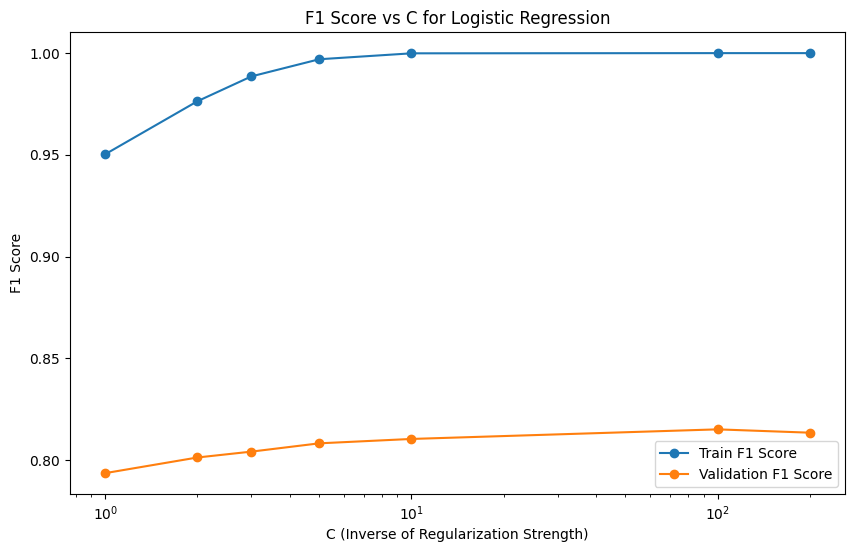

In [263]:
C_values = [1, 2, 3, 5, 10, 100, 200]
train_f1_scores = []
val_f1_scores = []
for C in C_values:
    model = LogisticRegression(C=C, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_f1= f1_score(y_train, model.predict(X_train_tfidf), average='weighted')
    val_f1 = f1_score(y_val, model.predict(X_val_tfidf), average='weighted')
    print(f"C={C}: Train F1 Score={train_f1:.4f}, Validation F1 Score={val_f1:.4f}")
    train_f1_scores.append(train_f1)
    val_f1_scores.append(val_f1)
    
plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_f1_scores, marker='o', label='Train F1 Score')
plt.plot(C_values, val_f1_scores, marker='o', label='Validation F1 Score')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('F1 Score')
plt.title('F1 Score vs C for Logistic Regression')
plt.legend()
plt.show()

### Insight
- Training F1 rises steadily as `C` increases peaking at **0.9999**. Validation F1 peaks around `C=100` **(0.8152)** and then declines, falling to about **0.8136** at `C=200`. This decline in validation is a clear sign of overfitting at large C.
 
- We choose `C=100` because it gives the **highest validation F1 score** and is the peak before the decline and overfitting starts to occur.


In [264]:
# Best settings, C=100
lr_model = LogisticRegression(C=100, random_state=RANDOM_STATE, max_iter=10000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(C=100, max_iter=10000, random_state=42)

## Linear SVM 

C=0.1: Train F1 Score=0.9466, Validation F1 Score=0.7942
C=0.5: Train F1 Score=0.9983, Validation F1 Score=0.8098
C=1: Train F1 Score=0.9999, Validation F1 Score=0.8100
C=2: Train F1 Score=0.9999, Validation F1 Score=0.8112
C=3: Train F1 Score=0.9999, Validation F1 Score=0.8129
C=5: Train F1 Score=0.9999, Validation F1 Score=0.8106
C=10: Train F1 Score=1.0000, Validation F1 Score=0.8101


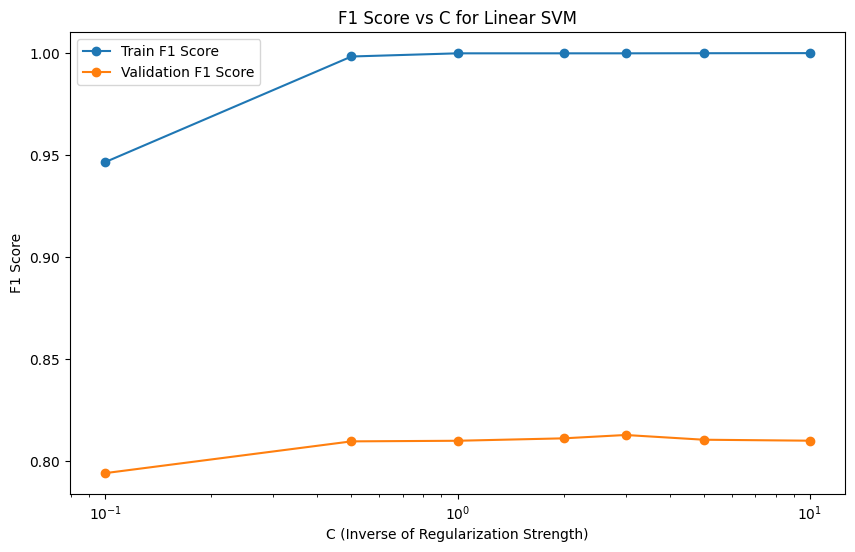

In [265]:
C_values = [0.1, 0.5, 1,2, 3, 5, 10]
train_f1_scores = []
val_f1_scores = []
for c in C_values:
    model = LinearSVC(C=c, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train_tfidf), average='weighted')
    val_f1 = f1_score(y_val, model.predict(X_val_tfidf), average='weighted')
    print(f"C={c}: Train F1 Score={train_f1:.4f}, Validation F1 Score={val_f1:.4f}")
    train_f1_scores.append(train_f1)
    val_f1_scores.append(val_f1)

plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_f1_scores, marker='o', label='Train F1 Score')
plt.plot(C_values, val_f1_scores, marker='o', label='Validation F1 Score')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('F1 Score')
plt.title('F1 Score vs C for Linear SVM')
plt.legend()
plt.show()

### Insight
- Validation F1 rises from `C=0.1` to a peak at `C=3` (0.8129), then declines slightly at `C=5`, while training F1 keeps rising so we stop at the validation peak to avoid overfitting.

- We choose `C=3` for the highest validation F1.

In [266]:
# Best settings, C=3
svm_model = LinearSVC(C=3, random_state=RANDOM_STATE, max_iter=10000)
svm_model.fit(X_train_tfidf, y_train)

LinearSVC(C=3, max_iter=10000, random_state=42)

## Ensemble of LR and SVM (Bonus)

In [272]:
from sklearn.ensemble import StackingClassifier

estimators = [
    ('lr', lr_model),
    ('svm', svm_model)
]

meta_model = LogisticRegression(random_state=RANDOM_STATE)

stacking_model = StackingClassifier(estimators=estimators, final_estimator=meta_model, cv=5)

stacking_model.fit(X_train_tfidf, y_train)
y_pred = stacking_model.predict(X_val_tfidf)

print("Training F1 Score:", f1_score(y_train, stacking_model.predict(X_train_tfidf)))
print("Validation F1 Score:", f1_score(y_val, y_pred))

Training F1 Score: 0.9998945926004006
Validation F1 Score: 0.8027310412094611


## Test Evaluation of 3 models

In [ ]:
models = {
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model,
    "Stacking (LR + SVM)": stacking_model,
}

class_names = ["Not Sarcastic", "Sarcastic"]
summary = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (sarcastic)": precision_score(y_test, y_pred),
        "Recall (sarcastic)": recall_score(y_test, y_pred),
        "F1 (sarcastic)": f1_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })

summary_df = pd.DataFrame(summary).set_index("Model").round(4)
summary_df



,Accuracy,Precision (sarcastic),Recall (sarcastic),F1 (sarcastic),F1 (macro)
Model,,,,,
Logistic Regression,0.8040,0.7959,0.7905,0.7932,0.8035
Linear SVM,0.8036,0.7960,0.7890,0.7925,0.8030
Stacking (LR + SVM),0.8059,0.7941,0.7988,0.7965,0.8055


In [318]:
for name, y_pred in predictions.items():
    print(f"\t\t{name}\n")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
    print("—"*55)

		Logistic Regression

               precision    recall  f1-score   support

Not Sarcastic     0.8113    0.8163    0.8138      2243
    Sarcastic     0.7959    0.7905    0.7932      2033

     accuracy                         0.8040      4276
    macro avg     0.8036    0.8034    0.8035      4276
 weighted avg     0.8040    0.8040    0.8040      4276

———————————————————————————————————————————————————————
		Linear SVM

               precision    recall  f1-score   support

Not Sarcastic     0.8103    0.8168    0.8135      2243
    Sarcastic     0.7960    0.7890    0.7925      2033

     accuracy                         0.8036      4276
    macro avg     0.8031    0.8029    0.8030      4276
 weighted avg     0.8035    0.8036    0.8035      4276

———————————————————————————————————————————————————————
		Stacking (LR + SVM)

               precision    recall  f1-score   support

Not Sarcastic     0.8167    0.8123    0.8145      2243
    Sarcastic     0.7941    0.7988    0.7965      2

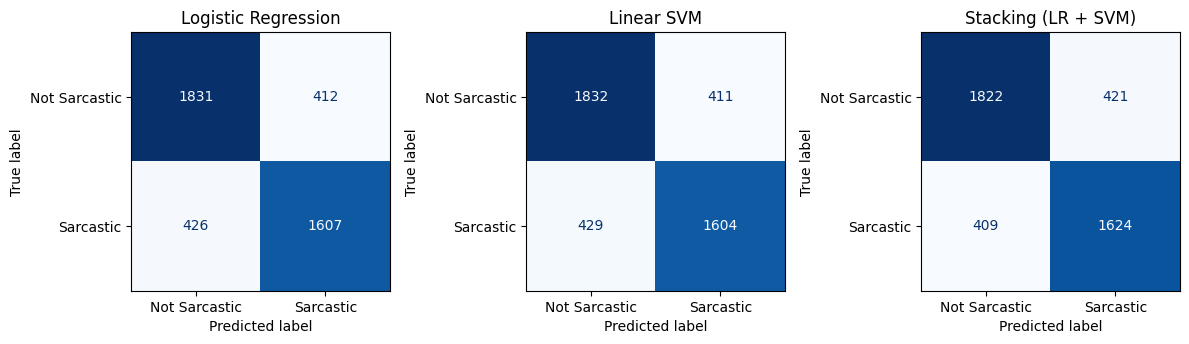

In [293]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Models Misclassification Analysis
- **Logistic Regression** and **Linear SVM** are pratically the same in numbers of correctly classified and missclassifed samples. The ensemble model is slightl better at **correctly classifying samples** (higher True Positives) and **lowering mistaking correct samples for incorrect ones** (lower False Positives) but it does worse at **correctly classifying incorrect samples** (lower True Negatives) and **mistaking incorrect samples for correct ones** (higher False Negatives).

In [319]:
# Top words affected that affect LR predictions
words = vectorizer.get_feature_names_out()
lr_coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({
    "Word": words,
    "Coefficient": lr_coefs
})
# Words that strongly indicate Class 1 (Sarcastic)
print("Top 10 positive coefficients (Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=False).head(10))

# Words that strongly indicate Class 0 (Not Sarcastic)
print("\nTop 10 negative coefficients (Not Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=True).head(10))

Top 10 positive coefficients (Sarcastic):


,Word,Coefficient
7121,area,41.318000
7182,area man,31.283578
75909,nation,27.560472
68829,man,26.707497
95520,report,21.950591
6038,announces,17.179981
45589,fucking,17.136203
66430,local,15.168292
104021,shit,14.951699
58325,introduces,14.891981



Top 10 negative coefficients (Not Sarcastic):


,Word,Coefficient
33644,donald trump,-23.975637
33638,donald,-22.627884
119427,trump,-14.864301
91887,queer,-12.961841
844,2015,-12.383456
2380,accused,-12.343344
118645,transgender,-12.209297
75334,muslim,-11.642784
76487,need,-11.226946
55205,huffpost,-11.120307


## Saving Vectorizer and Models

In [321]:
import joblib

joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")
joblib.dump(lr_model, "../models/logistic_regression_model.pkl")
joblib.dump(svm_model, "../models/linear_svm_model.pkl")
joblib.dump(stacking_model, "../models/stacking_model.pkl")

['../models/stacking_model.pkl']